**Мета роботи:** ознайомитися з побудовою та навчанням нейронних мереж для різних типів даних за допомогою PyTorch, дослідити процес навчання моделей і порівняти нейромережеві підходи з класичними алгоритмами машинного навчання.

У роботі розглядаються три задачі:
1. Класифікація популярності музичних композицій за допомогою MLP.
2. Класифікація зображень котів і собак за допомогою CNN та pretrained ResNet18.
3. Класифікація текстів 20 Newsgroups за допомогою GRU з випадковими та попередньо навченими GloVe embeddings.


## 0. Імпорт бібліотек і налаштування

In [ ]:
import os
import re
import random
import time
import copy

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Пристрій:", device)

Пристрій: cpu


# 1. Повнозв'язані нейронні мережі (MLP)

У першій частині використовується Spotify Tracks Dataset з лабораторної роботи №1. Задача формулюється як бінарна класифікація: визначити, чи є композиція популярною. Композиції з `popularity >= 50` належать до класу 1, решта — до класу 0.

Для навчання використовуються числові характеристики аудіо. Ідентифікатори, назви композицій та інші текстові поля не використовуються як ознаки.

## 1.1. Завантаження та огляд датасету

In [3]:
# За потреби змініть шлях до файлу
DATA_PATH = r"C:\Users\HP\Desktop\маг 1 курс\Аналіз\3\spotify-tracks-dataset.csv"

df = pd.read_csv(DATA_PATH)

print("Розмір датасету:", df.shape)
display(df.head())
print("\nНазви стовпців:")
print(df.columns.tolist())

Розмір датасету: (114000, 22)


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic



Назви стовпців:
['Unnamed: 0.1', 'Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']


## 1.2. Підготовка ознак і цільової змінної

In [ ]:
features = [
    "duration_ms", "explicit", "danceability", "energy", "key",
    "loudness", "mode", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo",
    "time_signature"
]

required_columns = features + ["popularity"]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"У датасеті відсутні стовпці: {missing_columns}")

df = df.dropna(subset=required_columns).copy()
df["target"] = (df["popularity"] >= 50).astype(int)

X = df[features].copy()
y = df["target"].copy()

sample_size = min(20000, len(X))

X_sample, _, y_sample, _ = train_test_split(
    X, y,
    train_size=sample_size,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Кількість записів:", len(X_sample))
print("\nРозподіл класів:")
print(y_sample.value_counts())
print("\nЧастки класів:")
print(y_sample.value_counts(normalize=True))

Кількість записів: 20000

Розподіл класів:
target
0    14848
1     5152
Name: count, dtype: int64

Частки класів:
target
0    0.7424
1    0.2576
Name: proportion, dtype: float64


## 1.3. Розбиття та масштабування даних

In [5]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X_sample, y_sample,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_sample
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_train_full
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)

y_train_t = torch.tensor(y_train.to_numpy(), dtype=torch.float32)
y_val_t = torch.tensor(y_val.to_numpy(), dtype=torch.float32)
y_test_t = torch.tensor(y_test.to_numpy(), dtype=torch.float32)

train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=128,
    shuffle=True
)
val_loader = DataLoader(
    TensorDataset(X_val_t, y_val_t),
    batch_size=256,
    shuffle=False
)

print("Train:", len(X_train_t))
print("Validation:", len(X_val_t))
print("Test:", len(X_test_t))

Train: 12800
Validation: 3200
Test: 4000


## 1.4. Побудова MLP

In [ ]:
class MLP(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x).squeeze(1)


mlp_model = MLP(X_train_t.shape[1]).to(device)

positive_count = float(y_train_t.sum())
negative_count = float(len(y_train_t) - positive_count)
pos_weight = torch.tensor([negative_count / max(positive_count, 1)], device=device)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=0.001)

print(mlp_model)

MLP(
  (network): Sequential(
    (0): Linear(in_features=14, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


## 1.5. Навчання MLP

In [7]:
def evaluate_binary_loss(model, loader, loss_function):
    model.eval()
    total_loss = 0.0

    with torch.no_grad():
        for batch_X, batch_y in loader:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            logits = model(batch_X)
            loss = loss_function(logits, batch_y)
            total_loss += loss.item() * len(batch_X)

    return total_loss / len(loader.dataset)


def train_binary_model(model, train_loader, val_loader, criterion, optimizer, epochs=30):
    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0

        for batch_X, batch_y in train_loader:
            batch_X = batch_X.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()
            logits = model(batch_X)
            loss = criterion(logits, batch_y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(batch_X)

        train_loss = total_loss / len(train_loader.dataset)
        val_loss = evaluate_binary_loss(model, val_loader, criterion)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        print(
            f"Епоха {epoch + 1:02d}/{epochs} | "
            f"train loss: {train_loss:.4f} | validation loss: {val_loss:.4f}"
        )

    return train_losses, val_losses


start_time = time.time()

mlp_train_losses, mlp_val_losses = train_binary_model(
    mlp_model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    epochs=30
)

mlp_training_time = time.time() - start_time
print(f"Час навчання: {mlp_training_time:.1f} с")

Епоха 01/30 | train loss: 1.0109 | validation loss: 0.9884
Епоха 02/30 | train loss: 0.9907 | validation loss: 0.9768
Епоха 03/30 | train loss: 0.9844 | validation loss: 0.9739
Епоха 04/30 | train loss: 0.9791 | validation loss: 0.9705
Епоха 05/30 | train loss: 0.9809 | validation loss: 0.9706
Епоха 06/30 | train loss: 0.9765 | validation loss: 0.9674
Епоха 07/30 | train loss: 0.9731 | validation loss: 0.9652
Епоха 08/30 | train loss: 0.9746 | validation loss: 0.9658
Епоха 09/30 | train loss: 0.9681 | validation loss: 0.9641
Епоха 10/30 | train loss: 0.9713 | validation loss: 0.9653
Епоха 11/30 | train loss: 0.9664 | validation loss: 0.9634
Епоха 12/30 | train loss: 0.9660 | validation loss: 0.9618
Епоха 13/30 | train loss: 0.9621 | validation loss: 0.9611
Епоха 14/30 | train loss: 0.9646 | validation loss: 0.9600
Епоха 15/30 | train loss: 0.9610 | validation loss: 0.9594
Епоха 16/30 | train loss: 0.9635 | validation loss: 0.9598
Епоха 17/30 | train loss: 0.9582 | validation loss: 0.95

## 1.6. Learning curves

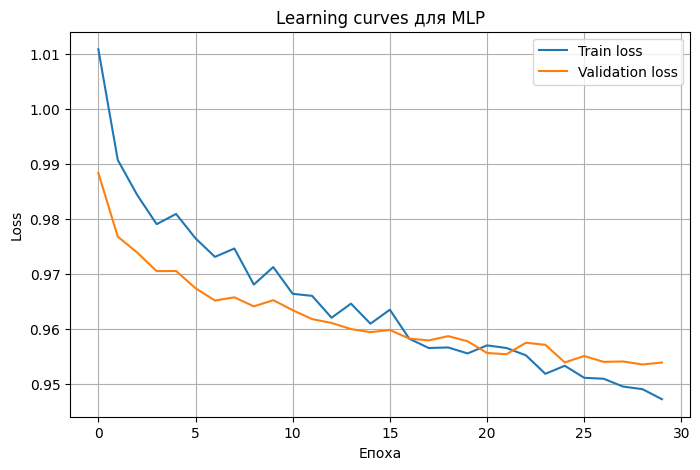

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(mlp_train_losses, label="Train loss")
plt.plot(mlp_val_losses, label="Validation loss")
plt.xlabel("Епоха")
plt.ylabel("Loss")
plt.title("Learning curves для MLP")
plt.legend()
plt.grid()
plt.show()

## 1.7. Оцінювання MLP на тестовій вибірці

In [9]:
mlp_model.eval()

with torch.no_grad():
    test_logits = mlp_model(X_test_t.to(device))
    mlp_probabilities = torch.sigmoid(test_logits).cpu().numpy()
    mlp_predictions = (mlp_probabilities >= 0.5).astype(int)

mlp_accuracy = accuracy_score(y_test, mlp_predictions)
mlp_f1 = f1_score(y_test, mlp_predictions)

print("MLP accuracy:", round(mlp_accuracy, 4))
print("MLP F1-score:", round(mlp_f1, 4))
print("\nClassification report:")
print(classification_report(y_test, mlp_predictions, zero_division=0))

MLP accuracy: 0.6178
MLP F1-score: 0.4568

Classification report:
              precision    recall  f1-score   support

           0       0.83      0.62      0.71      2970
           1       0.36      0.62      0.46      1030

    accuracy                           0.62      4000
   macro avg       0.59      0.62      0.58      4000
weighted avg       0.71      0.62      0.64      4000



## 1.8. Порівняння з класичними алгоритмами

Щоб порівняння було коректним, класичні моделі навчаються на тих самих навчальних даних і перевіряються на тій самій тестовій вибірці. Використовуються алгоритми з лабораторної №1: kNN, SVM, дерево рішень, Random Forest та AdaBoost.

In [10]:
classical_models = {
    "kNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(kernel="rbf", C=1.0, gamma="scale"),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=15, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "AdaBoost": AdaBoostClassifier(
        n_estimators=100, random_state=RANDOM_STATE
    )
}

comparison_results = []

for name, model in classical_models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    elapsed = time.time() - start_time

    comparison_results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "F1-score": f1_score(y_test, predictions),
        "Час навчання, с": elapsed
    })

comparison_results.append({
    "Модель": "MLP (PyTorch)",
    "Accuracy": mlp_accuracy,
    "F1-score": mlp_f1,
    "Час навчання, с": mlp_training_time
})

mlp_comparison = pd.DataFrame(comparison_results)
display(mlp_comparison.sort_values("F1-score", ascending=False))

c:\Users\HP\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


,Модель,Accuracy,F1-score,"Час навчання, с"
5,MLP (PyTorch),0.61775,0.456838,18.823218
2,Decision Tree,0.70100,0.288095,0.184317
0,kNN,0.70075,0.287924,0.966352
3,Random Forest,0.76275,0.236525,1.717669
4,AdaBoost,0.73975,0.061317,1.863114
1,SVM,0.74500,0.043152,11.816206


# 2. Згорткові нейронні мережі (CNN)

Для класифікації зображень використовується **Oxford-IIIT Pet Dataset**. Він містить фотографії котів і собак 37 порід: 12 порід котів та 25 порід собак. Для кожного зображення задано одну з 37 категорій.

У цій частині буде побудовано CNN з нуля та використано попередньо навчену ResNet18. Для обох моделей оцінюється якість класифікації та аналізуються learning curves.

## 2.1. Завантаження датасету

In [11]:
from torchvision import datasets, transforms
from torch.utils.data import Subset

IMAGE_SIZE = 128
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

data_root = "./data"

trainval_aug = datasets.OxfordIIITPet(
    root=data_root,
    split="trainval",
    target_types="category",
    transform=train_transform,
    download=True
)

trainval_eval = datasets.OxfordIIITPet(
    root=data_root,
    split="trainval",
    target_types="category",
    transform=eval_transform,
    download=False
)

test_dataset = datasets.OxfordIIITPet(
    root=data_root,
    split="test",
    target_types="category",
    transform=eval_transform,
    download=True
)

class_names = trainval_aug.classes
num_classes = len(class_names)

print("Кількість класів:", num_classes)
print("Кількість зображень trainval:", len(trainval_aug))
print("Кількість зображень test:", len(test_dataset))
print("Класи:", class_names)

100%|██████████| 792M/792M [01:58<00:00, 6.67MB/s] 
100%|██████████| 19.2M/19.2M [00:14<00:00, 1.31MB/s]


Кількість класів: 37
Кількість зображень trainval: 3680
Кількість зображень test: 3669
Класи: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair', 'Chihuahua', 'Egyptian Mau', 'English Cocker Spaniel', 'English Setter', 'German Shorthaired', 'Great Pyrenees', 'Havanese', 'Japanese Chin', 'Keeshond', 'Leonberger', 'Maine Coon', 'Miniature Pinscher', 'Newfoundland', 'Persian', 'Pomeranian', 'Pug', 'Ragdoll', 'Russian Blue', 'Saint Bernard', 'Samoyed', 'Scottish Terrier', 'Shiba Inu', 'Siamese', 'Sphynx', 'Staffordshire Bull Terrier', 'Wheaten Terrier', 'Yorkshire Terrier']


## 2.2. Поділ на навчальну та validation вибірки

In [12]:
indices = np.arange(len(trainval_aug))
train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=trainval_aug._labels
)

train_dataset = Subset(trainval_aug, train_indices)
val_dataset = Subset(trainval_eval, val_indices)

train_image_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
val_image_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
test_image_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 2944
Validation: 736
Test: 3669


## 2.3. Візуалізація прикладів зображень

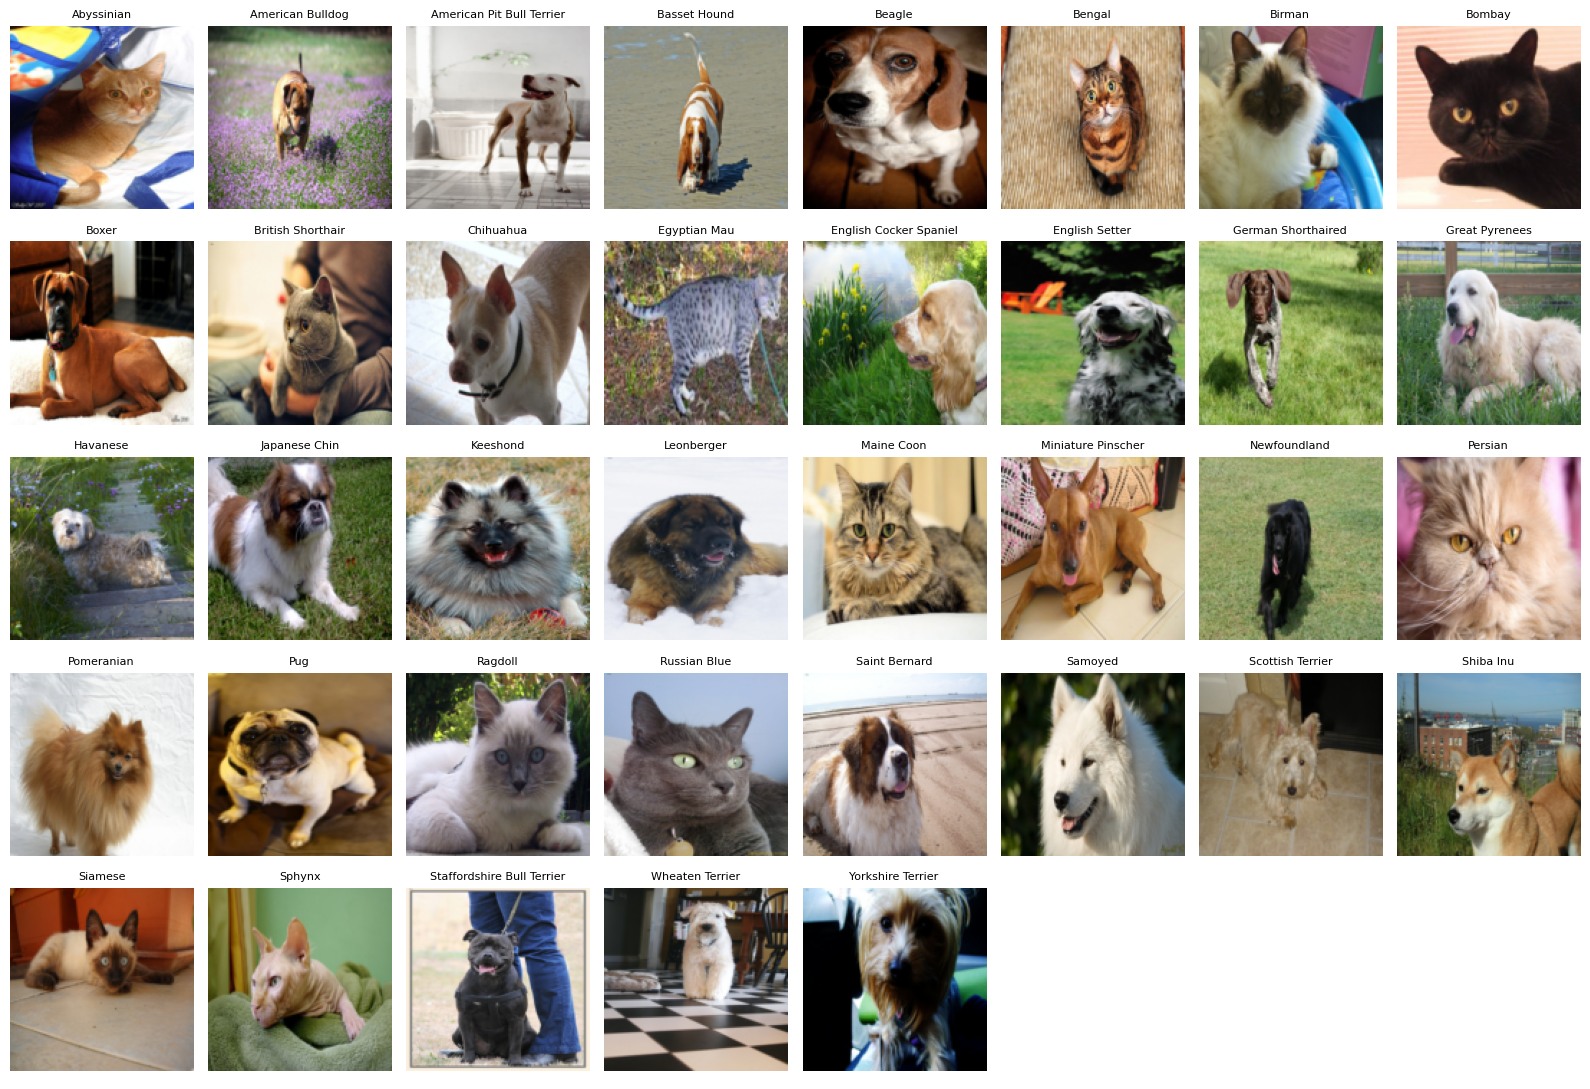

In [ ]:
fig, axes = plt.subplots(5, 8, figsize=(16, 11))
axes = axes.ravel()

shown = set()

for image, label in trainval_eval:
    if label not in shown:
        image = image.permute(1, 2, 0).numpy()
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        image = np.clip(image * std + mean, 0, 1)

        ax = axes[label]
        ax.imshow(image)
        ax.set_title(class_names[label], fontsize=8)
        ax.axis("off")
        shown.add(label)

    if len(shown) == num_classes:
        break

for i in range(num_classes, len(axes)):
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## 2.4. Функції навчання та оцінювання CNN

In [14]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        if training:
            optimizer.zero_grad()

        with torch.set_grad_enabled(training):
            outputs = model(images)
            loss = criterion(outputs, labels)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


def train_multiclass_model(model, train_loader, val_loader, epochs, learning_rate):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=learning_rate
    )

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    start = time.time()

    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(
            model, train_loader, criterion, optimizer
        )
        val_loss, val_acc = run_epoch(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(
            f"Епоха {epoch + 1}/{epochs} | "
            f"train loss: {train_loss:.4f}, val loss: {val_loss:.4f} | "
            f"train acc: {train_acc:.4f}, val acc: {val_acc:.4f}"
        )

    elapsed = time.time() - start
    return model, history, elapsed


def plot_learning_curves(history, title):
    plt.figure(figsize=(8, 5))
    plt.plot(history["train_loss"], label="Train loss")
    plt.plot(history["val_loss"], label="Validation loss")
    plt.xlabel("Епоха")
    plt.ylabel("Loss")
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()


def predict_multiclass(model, loader):
    model.eval()
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            predictions = outputs.argmax(dim=1).cpu().numpy()
            all_predictions.extend(predictions)
            all_labels.extend(labels.numpy())

    return np.array(all_labels), np.array(all_predictions)

## 2.5. CNN, навчена з нуля

In [15]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)
        return self.classifier(x)


cnn_model = SimpleCNN(num_classes)

cnn_model, cnn_history, cnn_time = train_multiclass_model(
    cnn_model,
    train_image_loader,
    val_image_loader,
    epochs=5,
    learning_rate=0.001
)

print(f"Час навчання CNN: {cnn_time:.1f} с")

Епоха 1/5 | train loss: 3.6129, val loss: 3.5980 | train acc: 0.0265, val acc: 0.0421
Епоха 2/5 | train loss: 3.5734, val loss: 3.5428 | train acc: 0.0445, val acc: 0.0367
Епоха 3/5 | train loss: 3.5339, val loss: 3.5382 | train acc: 0.0520, val acc: 0.0571
Епоха 4/5 | train loss: 3.5089, val loss: 3.4907 | train acc: 0.0581, val acc: 0.0693
Епоха 5/5 | train loss: 3.4716, val loss: 3.4792 | train acc: 0.0611, val acc: 0.0707
Час навчання CNN: 327.1 с


## 2.6. Learning curves для CNN

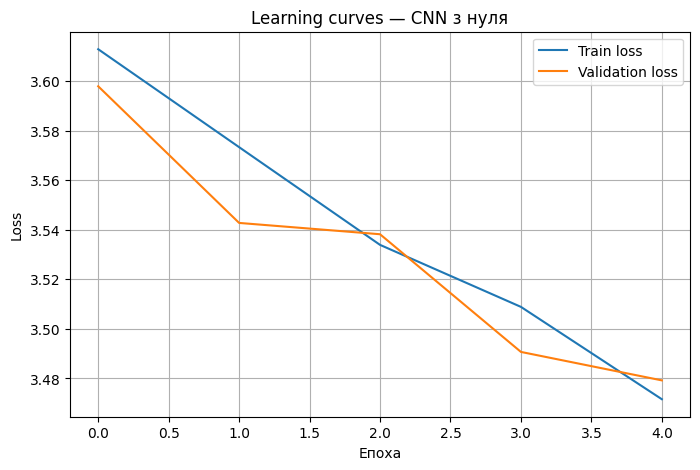

In [16]:
plot_learning_curves(cnn_history, "Learning curves — CNN з нуля")

## 2.7. Оцінювання CNN на тестовій вибірці

In [17]:
cnn_true, cnn_pred = predict_multiclass(cnn_model, test_image_loader)

cnn_accuracy = accuracy_score(cnn_true, cnn_pred)
cnn_f1 = f1_score(cnn_true, cnn_pred, average="macro")

print("CNN test accuracy:", round(cnn_accuracy, 4))
print("CNN test macro F1:", round(cnn_f1, 4))

CNN test accuracy: 0.0681
CNN test macro F1: 0.0447


## 2.8. Pretrained модель ResNet18

ResNet18 завантажується з вагами, попередньо навченими на ImageNet. Вихідний класифікаційний шар замінюється на новий, який має 37 виходів — по одному для кожної породи. Для зменшення часу навчання основна частина мережі заморожується, а останній residual-блок і новий класифікатор донавчаються на нашому датасеті.

In [18]:
from torchvision.models import resnet18, ResNet18_Weights

weights = ResNet18_Weights.DEFAULT
resnet_model = resnet18(weights=weights)

for parameter in resnet_model.parameters():
    parameter.requires_grad = False

for parameter in resnet_model.layer4.parameters():
    parameter.requires_grad = True

resnet_model.fc = nn.Linear(resnet_model.fc.in_features, num_classes)

resnet_model, resnet_history, resnet_time = train_multiclass_model(
    resnet_model,
    train_image_loader,
    val_image_loader,
    epochs=5,
    learning_rate=0.0001
)

print(f"Час навчання ResNet18: {resnet_time:.1f} с")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\HP/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:05<00:00, 7.94MB/s]


Епоха 1/5 | train loss: 2.3416, val loss: 1.3322 | train acc: 0.4283, val acc: 0.6603
Епоха 2/5 | train loss: 0.9477, val loss: 0.9609 | train acc: 0.7969, val acc: 0.7418
Епоха 3/5 | train loss: 0.5230, val loss: 0.8369 | train acc: 0.9083, val acc: 0.7649
Епоха 4/5 | train loss: 0.2911, val loss: 0.7968 | train acc: 0.9572, val acc: 0.7717
Епоха 5/5 | train loss: 0.1651, val loss: 0.7822 | train acc: 0.9878, val acc: 0.7622
Час навчання ResNet18: 368.9 с


## 2.9. Learning curves для ResNet18

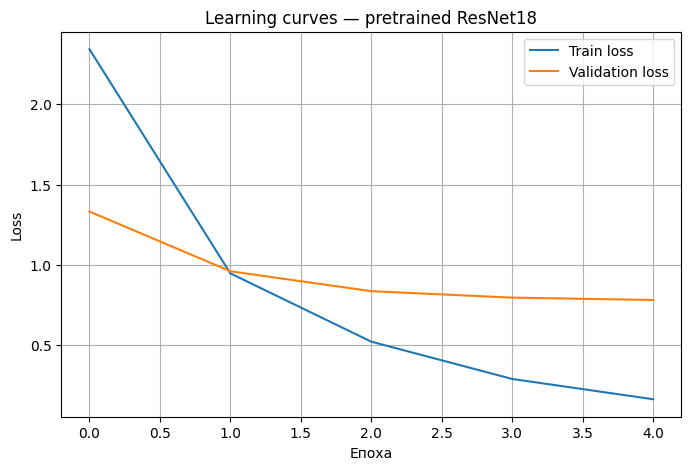

In [19]:
plot_learning_curves(resnet_history, "Learning curves — pretrained ResNet18")

## 2.10. Оцінювання ResNet18

In [20]:
resnet_true, resnet_pred = predict_multiclass(
    resnet_model, test_image_loader
)

resnet_accuracy = accuracy_score(resnet_true, resnet_pred)
resnet_f1 = f1_score(resnet_true, resnet_pred, average="macro")

print("ResNet18 test accuracy:", round(resnet_accuracy, 4))
print("ResNet18 test macro F1:", round(resnet_f1, 4))

ResNet18 test accuracy: 0.7302
ResNet18 test macro F1: 0.73


## 2.11. Порівняння CNN і ResNet18

In [21]:
cnn_comparison = pd.DataFrame([
    {
        "Модель": "CNN з нуля",
        "Accuracy": cnn_accuracy,
        "Macro F1": cnn_f1,
        "Час навчання, с": cnn_time
    },
    {
        "Модель": "Pretrained ResNet18",
        "Accuracy": resnet_accuracy,
        "Macro F1": resnet_f1,
        "Час навчання, с": resnet_time
    }
])

display(cnn_comparison)

,Модель,Accuracy,Macro F1,"Час навчання, с"
0,CNN з нуля,0.068138,0.044737,327.051386
1,Pretrained ResNet18,0.730172,0.730017,368.916274


## 2.12. Вплив обсягу навчальних даних

Попередньо навчені моделі зазвичай потребують менше спеціалізованих навчальних даних, оскільки вже мають ознаки, отримані під час навчання на великому наборі зображень. У цій роботі ResNet18 використовує перенесення навчання: більшість її шарів заморожена, а останній блок і класифікатор донавчаються.

Для експериментальної перевірки можна повторити навчання обох моделей на меншій підвибірці, наприклад 25% навчальних зображень, і порівняти отримані метрики. Основне порівняння моделей наведено вище.

# 3. Нейронні мережі для класифікації текстів

У третій частині використовується той самий текстовий датасет **20 Newsgroups**, що й у лабораторній роботі №2. Для експерименту залишаються чотири категорії: хокей, космос, комп'ютерна графіка та політика.

Тексти перетворюються на послідовності індексів слів. Для класифікації використовується GRU. Спочатку embedding layer ініціалізується випадковими вагами, після чого проводиться експеримент із попередньо навченими GloVe embeddings.

## 3.1. Завантаження текстового датасету

In [22]:
from sklearn.datasets import fetch_20newsgroups

categories = [
    "rec.sport.hockey",
    "sci.space",
    "comp.graphics",
    "talk.politics.misc"
]

train_data = fetch_20newsgroups(
    subset="train",
    categories=categories,
    remove=("headers", "footers", "quotes"),
    shuffle=True,
    random_state=RANDOM_STATE
)

test_data = fetch_20newsgroups(
    subset="test",
    categories=categories,
    remove=("headers", "footers", "quotes"),
    shuffle=True,
    random_state=RANDOM_STATE
)

X_text_train = train_data.data
y_text_train = np.asarray(train_data.target)

X_text_test = test_data.data
y_text_test = np.asarray(test_data.target)

target_names = train_data.target_names

print("Кількість текстів у train:", len(X_text_train))
print("Кількість текстів у test:", len(X_text_test))
print("Класи:", target_names)
print("\nПриклад тексту:")
print(X_text_train[0][:1000])

Кількість текстів у train: 2242
Кількість текстів у test: 1492
Класи: ['comp.graphics', 'rec.sport.hockey', 'sci.space', 'talk.politics.misc']

Приклад тексту:
Pascal Perret, in article <1993Apr21.125750.263@eicn.etna.ch>, wrote

Funny thing, the InterNet: I have no idea what xv221 might be - except that it
might be something to do with X-windows on PCs (? If you know, and have used
it, and think that it is good, email me. [ryanph@mrl.dsto.gov.au]).

DV/X is a common abbreviation for QuarterDeck corporation's Desqview/X
software.

I have not used DV/X yet, but reading the blurbs that Quarterdeck sent me, it
sounds pretty great:
	* allows multiple DOS machines - the way that OS/2 does, but without
requiring 10 MB of RAM to get OS/2 going
	* pre-emptive multi-tasking
	* network computing - a proper X-windows client/server application -
this means that DOS program can be used on other X-windows computers on your
network, and that X-windows programs can be used on your DV/X computer
	* alt

## 3.2. Передобробка текстів і токенізація

In [23]:
def tokenize(text):
    text = text.lower()
    return re.findall(r"[a-z]+", text)


train_tokens = [tokenize(text) for text in X_text_train]
test_tokens = [tokenize(text) for text in X_text_test]

print("Початковий текст:")
print(X_text_train[0][:300])
print("\nТокени:")
print(train_tokens[0][:30])

Початковий текст:
Pascal Perret, in article <1993Apr21.125750.263@eicn.etna.ch>, wrote

Funny thing, the InterNet: I have no idea what xv221 might be - except that it
might be something to do with X-windows on PCs (? If you know, and have used
it, and think that it is good, email me. [ryanph@mrl.dsto.gov.au]).

DV/X 

Токени:
['pascal', 'perret', 'in', 'article', 'apr', 'eicn', 'etna', 'ch', 'wrote', 'funny', 'thing', 'the', 'internet', 'i', 'have', 'no', 'idea', 'what', 'xv', 'might', 'be', 'except', 'that', 'it', 'might', 'be', 'something', 'to', 'do', 'with']


## 3.3. Побудова словника

In [24]:
from collections import Counter

MAX_VOCAB_SIZE = 20000
MIN_FREQ = 2
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

word_counts = Counter(
    token
    for document in train_tokens
    for token in document
)

vocab = {
    PAD_TOKEN: 0,
    UNK_TOKEN: 1
}

for word, count in word_counts.most_common(MAX_VOCAB_SIZE):
    if count < MIN_FREQ:
        break
    if word not in vocab:
        vocab[word] = len(vocab)

print("Розмір словника:", len(vocab))

Розмір словника: 14758


## 3.4. Перетворення текстів на послідовності однакової довжини

In [25]:
MAX_LENGTH = 250

def encode_and_pad(tokens, vocab, max_length=MAX_LENGTH):
    sequence = [vocab.get(token, vocab[UNK_TOKEN]) for token in tokens]
    sequence = sequence[:max_length]

    if len(sequence) < max_length:
        sequence += [vocab[PAD_TOKEN]] * (max_length - len(sequence))

    return sequence


X_train_ids = np.array([
    encode_and_pad(tokens, vocab) for tokens in train_tokens
])

X_test_ids = np.array([
    encode_and_pad(tokens, vocab) for tokens in test_tokens
])

print("Розмір train:", X_train_ids.shape)
print("Розмір test:", X_test_ids.shape)

Розмір train: (2242, 250)
Розмір test: (1492, 250)


## 3.5. Формування train і validation вибірок

In [26]:
X_train_text, X_val_text, y_train_text, y_val_text = train_test_split(
    X_train_ids,
    y_text_train,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_text_train
)

X_train_text = torch.tensor(X_train_text, dtype=torch.long)
X_val_text = torch.tensor(X_val_text, dtype=torch.long)
X_test_text = torch.tensor(X_test_ids, dtype=torch.long)

y_train_text = torch.tensor(y_train_text, dtype=torch.long)
y_val_text = torch.tensor(y_val_text, dtype=torch.long)
y_test_text = torch.tensor(y_text_test, dtype=torch.long)

text_train_loader = DataLoader(
    TensorDataset(X_train_text, y_train_text),
    batch_size=64,
    shuffle=True
)

text_val_loader = DataLoader(
    TensorDataset(X_val_text, y_val_text),
    batch_size=128,
    shuffle=False
)

text_test_loader = DataLoader(
    TensorDataset(X_test_text, y_test_text),
    batch_size=128,
    shuffle=False
)

print("Train:", len(X_train_text))
print("Validation:", len(X_val_text))
print("Test:", len(X_test_text))

Train: 1793
Validation: 449
Test: 1492


## 3.6. Модель GRU з випадковою ініціалізацією Embedding

In [39]:
class GRUClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        num_classes,
        embedding_matrix=None
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        if embedding_matrix is not None:
            self.embedding.weight.data.copy_(
                torch.tensor(embedding_matrix, dtype=torch.float32)
            )

        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):
        lengths = (x != 0).sum(dim=1).cpu()

        embedded = self.embedding(x)

        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.clamp(min=1),
            batch_first=True,
            enforce_sorted=False
        )

        _, hidden = self.gru(packed)

        hidden = torch.cat((hidden[-2], hidden[-1]), dim=1)

        return self.fc(self.dropout(hidden))


EMBEDDING_DIM = 50
HIDDEN_DIM = 64
NUM_CLASSES = len(target_names)

gru_random = GRUClassifier(
    vocab_size=len(vocab),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=NUM_CLASSES
).to(device)

print(gru_random)

GRUClassifier(
  (embedding): Embedding(14758, 50, padding_idx=0)
  (gru): GRU(50, 64, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=4, bias=True)
)


## 3.7. Функції навчання та оцінювання текстових моделей

In [37]:
def train_text_model(model, train_loader, val_loader, epochs=8):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    start = time.time()

    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for texts, labels in train_loader:
            texts = texts.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(texts)
            loss = criterion(outputs, labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            train_loss += loss.item() * labels.size(0)
            train_correct += (outputs.argmax(1) == labels).sum().item()
            train_total += labels.size(0)

        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for texts, labels in val_loader:
                texts = texts.to(device)
                labels = labels.to(device)

                outputs = model(texts)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * labels.size(0)
                val_correct += (outputs.argmax(1) == labels).sum().item()
                val_total += labels.size(0)

        train_loss /= train_total
        val_loss /= val_total
        train_acc = train_correct / train_total
        val_acc = val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(
            f"Епоха {epoch + 1}/{epochs} | "
            f"train loss: {train_loss:.4f}, val loss: {val_loss:.4f} | "
            f"train acc: {train_acc:.4f}, val acc: {val_acc:.4f}"
        )

    return model, history, time.time() - start


def evaluate_text_model(model, loader):
    model.eval()
    predictions = []
    labels_all = []

    with torch.no_grad():
        for texts, labels in loader:
            outputs = model(texts.to(device))
            predictions.extend(outputs.argmax(1).cpu().numpy())
            labels_all.extend(labels.numpy())

    return np.array(labels_all), np.array(predictions)

## 3.8. Навчання GRU з випадковими Embedding

Епоха 1/8 | train loss: 1.3726, val loss: 1.3375 | train acc: 0.3001, val acc: 0.3430
Епоха 2/8 | train loss: 1.3048, val loss: 1.3058 | train acc: 0.3999, val acc: 0.3831
Епоха 3/8 | train loss: 1.2428, val loss: 1.2769 | train acc: 0.4490, val acc: 0.4076
Епоха 4/8 | train loss: 1.1746, val loss: 1.2473 | train acc: 0.5020, val acc: 0.4276
Епоха 5/8 | train loss: 1.0618, val loss: 1.1613 | train acc: 0.5728, val acc: 0.4833
Епоха 6/8 | train loss: 0.8915, val loss: 1.0539 | train acc: 0.6537, val acc: 0.5523
Епоха 7/8 | train loss: 0.7623, val loss: 0.9882 | train acc: 0.7128, val acc: 0.5880
Епоха 8/8 | train loss: 0.6329, val loss: 0.9333 | train acc: 0.7747, val acc: 0.6169


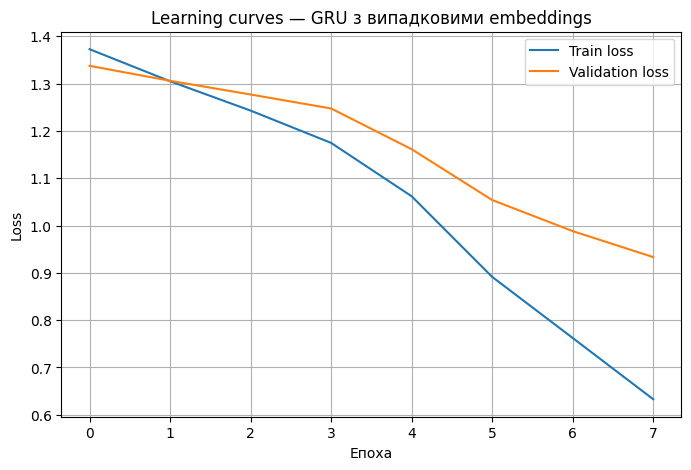

GRU random embeddings accuracy: 0.5784
GRU random embeddings macro F1: 0.563


In [40]:
gru_random, gru_random_history, gru_random_time = train_text_model(
    gru_random,
    text_train_loader,
    text_val_loader,
    epochs=8
)

plot_learning_curves(
    gru_random_history,
    "Learning curves — GRU з випадковими embeddings"
)

text_true, random_pred = evaluate_text_model(
    gru_random, text_test_loader
)

random_accuracy = accuracy_score(text_true, random_pred)
random_f1 = f1_score(text_true, random_pred, average="macro")

print("GRU random embeddings accuracy:", round(random_accuracy, 4))
print("GRU random embeddings macro F1:", round(random_f1, 4))

## 3.9. Завантаження pretrained GloVe embeddings

In [ ]:
import scipy.linalg
if not hasattr(scipy.linalg, "triu"):
    scipy.linalg.triu = np.triu

import gensim.downloader as api

glove = api.load("glove-wiki-gigaword-50")
print("Кількість pretrained векторів:", len(glove))
print("Розмірність вектора:", glove.vector_size)

[==================================================] 100.0% 66.0/66.0MB downloaded
Кількість pretrained векторів: 400000
Розмірність вектора: 50


## 3.10. Створення матриці pretrained embeddings

In [31]:
embedding_matrix = np.random.normal(
    scale=0.1,
    size=(len(vocab), EMBEDDING_DIM)
).astype(np.float32)

embedding_matrix[vocab[PAD_TOKEN]] = np.zeros(EMBEDDING_DIM)

found_words = 0

for word, index in vocab.items():
    if word in glove:
        embedding_matrix[index] = glove[word]
        found_words += 1

print("Слів у словнику:", len(vocab))
print("Слів із pretrained векторами:", found_words)
print("Частка знайдених слів:", round(found_words / len(vocab), 3))

Слів у словнику: 14758
Слів із pretrained векторами: 13842
Частка знайдених слів: 0.938


## 3.11. GRU з pretrained Embedding

Епоха 1/8 | train loss: 1.3526, val loss: 1.3177 | train acc: 0.3503, val acc: 0.4454
Епоха 2/8 | train loss: 1.2089, val loss: 1.1044 | train acc: 0.4953, val acc: 0.5078
Епоха 3/8 | train loss: 0.8823, val loss: 0.7813 | train acc: 0.6297, val acc: 0.6837
Епоха 4/8 | train loss: 0.6590, val loss: 0.6531 | train acc: 0.7256, val acc: 0.7439
Епоха 5/8 | train loss: 0.5397, val loss: 0.5476 | train acc: 0.7953, val acc: 0.8129
Епоха 6/8 | train loss: 0.4049, val loss: 0.5465 | train acc: 0.8606, val acc: 0.7951
Епоха 7/8 | train loss: 0.3095, val loss: 0.4530 | train acc: 0.8907, val acc: 0.8307
Епоха 8/8 | train loss: 0.2672, val loss: 0.4128 | train acc: 0.9052, val acc: 0.8664


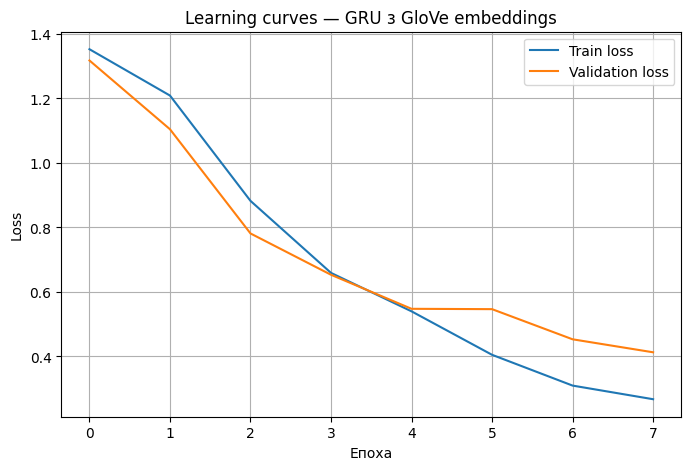

GRU GloVe accuracy: 0.8512
GRU GloVe macro F1: 0.847


In [32]:
gru_glove = GRUClassifier(
    vocab_size=len(vocab),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    num_classes=NUM_CLASSES,
    embedding_matrix=embedding_matrix
).to(device)

gru_glove, gru_glove_history, gru_glove_time = train_text_model(
    gru_glove,
    text_train_loader,
    text_val_loader,
    epochs=8
)

plot_learning_curves(
    gru_glove_history,
    "Learning curves — GRU з GloVe embeddings"
)

text_true, glove_pred = evaluate_text_model(
    gru_glove, text_test_loader
)

glove_accuracy = accuracy_score(text_true, glove_pred)
glove_f1 = f1_score(text_true, glove_pred, average="macro")

print("GRU GloVe accuracy:", round(glove_accuracy, 4))
print("GRU GloVe macro F1:", round(glove_f1, 4))

## 3.12. Порівняння моделей для текстів

In [33]:
text_comparison = pd.DataFrame([
    {
        "Модель": "GRU — random embeddings",
        "Accuracy": random_accuracy,
        "Macro F1": random_f1,
        "Час навчання, с": gru_random_time
    },
    {
        "Модель": "GRU — GloVe embeddings",
        "Accuracy": glove_accuracy,
        "Macro F1": glove_f1,
        "Час навчання, с": gru_glove_time
    }
])

display(text_comparison)

,Модель,Accuracy,Macro F1,"Час навчання, с"
0,GRU — random embeddings,0.454424,0.427367,135.539103
1,GRU — GloVe embeddings,0.851206,0.847034,120.615084


# 4. Загальні висновки

У лабораторній роботі було розглянуто три підходи до класифікації різних типів даних за допомогою PyTorch.

1. Для табличних даних Spotify було побудовано повнозв'язану нейронну мережу MLP та порівняно її результати з класичними алгоритмами машинного навчання.
2. Для зображень Oxford-IIIT Pet було реалізовано CNN з нуля та модель ResNet18 з попередньо навченими вагами.
3. Для текстів 20 Newsgroups було побудовано GRU з випадковими embeddings і з попередньо навченими GloVe embeddings.


